# Streaming demo: a buffered decision tree on the Housing data

| Requirement | Section |
|---|---|
| Load a CSV with the custom I/O pipeline (`io.py`, built on the Assignment 2.1 reader) | 1 |
| Split the dataset into chunks to simulate a stream | 2 |
| Train the pipeline incrementally with `.partial_fit()` on each chunk | 4-5 |
| Log and visualise metrics over time with `visualise.py` (accuracy, error, model comparison) | 5-7 |

**Data** (`Dataset/Housing.csv`, the dataset of Assignment 2.1): 545 houses with price, area, rooms and yes/no features. About 14 cells are missing. The label to predict is `airconditioning` (`yes` / `no`).

**The file is sorted by price, from high to low.** Streamed in file order, the first chunks hold the most expensive houses and the last chunks the cheapest. So the data changes over the stream, as in a real stream where the world changes.

**Model**: `DecisionTreeClassifier(max_depth=4, buffer_size=...)`. Each `partial_fit` adds a chunk to a buffer. When the buffer holds `buffer_size` samples, the tree is retrained on them and the buffer is cleared.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np

ROOT = Path.cwd() if (Path.cwd() / "numcompute_stream").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # the repository root, so numcompute and numcompute_stream can be imported

from numcompute.io import DEFAULT_MISSING_VALUES  # Assignment 2.1
from numcompute_stream import (AUC, DecisionTreeClassifier, Imputer, OneHotEncoder, Pipeline, StandardScaler,
                               StreamingStats, StreamTrainer, iter_chunks, load_csv)
from numcompute_stream import visualise as vis

FIGURES = ROOT / "demo_stream" / "figures"
FIGURES.mkdir(exist_ok=True)

## 1. Load the CSV with `io.py`
`load_csv` reads the file with the Assignment 2.1 reader `numcompute.io.read_csv`. Numeric columns become floats with NaN for missing cells, and text columns stay text. The file also writes some missing cells as `NAN`, so that token is added to the 2.1 list of missing values.

In [2]:
TARGET = "airconditioning"
TEXT_COLUMNS = ["mainroad", "guestroom", "basement", "hotwaterheating", "prefarea", "furnishingstatus"]
MISSING = (*DEFAULT_MISSING_VALUES, "NAN")

X, y, feature_names = load_csv(ROOT / "Dataset" / "Housing.csv", target_column=TARGET, missing_values=MISSING)
text_columns = [feature_names.index(name) for name in TEXT_COLUMNS]
numeric_columns = [j for j in range(len(feature_names)) if j not in text_columns]

print("X shape:", X.shape, "| features:", feature_names)
labels, counts = np.unique(y, return_counts=True)
print("labels:", dict(zip(labels.tolist(), counts.tolist())), "(rows without a label were dropped)")
print("missing numeric values:", {feature_names[j]: int(np.isnan(X[:, j].astype(float)).sum()) for j in numeric_columns
                                  if np.isnan(X[:, j].astype(float)).any()})
print("missing text values:   ", {feature_names[j]: int((X[:, j] == "").sum()) for j in text_columns if (X[:, j] == "").any()})
print("price of the first and last house:", X[0, 0], X[-1, 0])

X shape: (544, 12) | features: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'parking', 'prefarea', 'furnishingstatus']
labels: {'no': 373, 'yes': 171} (rows without a label were dropped)
missing numeric values: {'area': 1, 'bedrooms': 3, 'bathrooms': 2, 'stories': 1, 'parking': 3}
missing text values:    {'mainroad': 2, 'guestroom': 1, 'basement': 4, 'hotwaterheating': 1, 'prefarea': 1}
price of the first and last house: 13300000.0 1750000.0


## 2. Split the dataset into chunks
The original order is kept, so the stream goes from expensive to cheap houses.

In [3]:
CHUNK_SIZE = 25
chunks = list(iter_chunks(X, y, CHUNK_SIZE))
print(f"{len(chunks)} chunks of {CHUNK_SIZE} rows (the last one has {len(chunks[-1][1])})")

22 chunks of 25 rows (the last one has 19)


## 3. Streaming statistics with `update_stats`
The statistics are computed in one pass, chunk by chunk, without keeping all the data.

In [4]:
stats = StreamingStats(random_state=0)
for X_chunk, _ in chunks:
    stats.update_stats(X_chunk[:, numeric_columns].astype(float))

summary = stats.summary()
for k, j in enumerate(numeric_columns):
    print(f"{feature_names[j]:<10} mean {summary['mean'][k]:12.1f}   std {summary['std'][k]:12.1f}   "
          f"median {summary['median'][k]:12.1f}   missing {summary['missing'][k]}")

price      mean    4761594.6   std    1866594.6   median    4340000.0   missing 0
area       mean       5134.2   std       2144.1   median       4560.0   missing 1
bedrooms   mean          3.0   std          0.7   median          3.0   missing 3
bathrooms  mean          1.3   std          0.5   median          1.0   missing 2
stories    mean          1.8   std          0.9   median          2.0   missing 1
parking    mean          0.7   std          0.9   median          0.0   missing 3


**How the stream changes.** The share of houses with air conditioning in each chunk drops as the prices fall. A model trained on the first chunks has seen a different mix from the one it meets later.

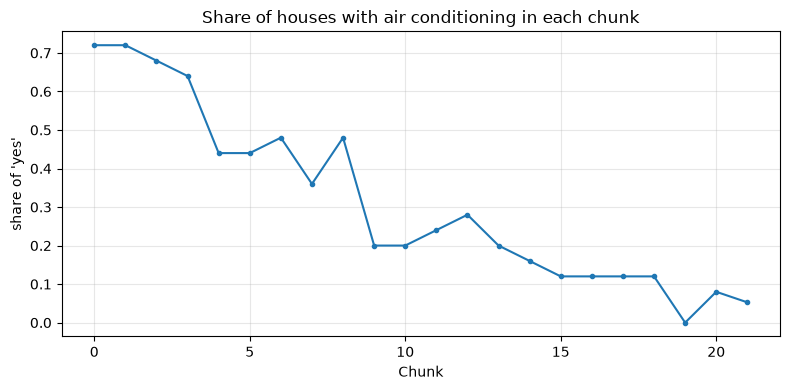

In [5]:
yes_share = np.array([np.mean(y_chunk == "yes") for _, y_chunk in chunks])
vis.plot_metric_over_time(yes_share, title="Share of houses with air conditioning in each chunk",
                          ylabel="share of 'yes'", save_path=FIGURES / "label_share_per_chunk.png");

## 4. The pipeline and buffered retraining with `partial_fit`
* `OneHotEncoder(columns=..., max_categories=3)` encodes the six text columns. Three fixed slots per column keep the number of features constant (`furnishingstatus` has three values, the yes/no columns use two).
* `Imputer` and `StandardScaler` update their running statistics with every chunk.
* `DecisionTreeClassifier(max_depth=4, buffer_size=100)` collects chunks and retrains when 100 samples are waiting.

Watch the buffer fill up and the tree retrain:

In [6]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("encode", OneHotEncoder(columns=text_columns, max_categories=3)),
        ("impute", Imputer()),
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=4, buffer_size=buffer_size)),
    ])

pipe = make_pipeline(buffer_size=100)
tree = pipe.named_steps["model"]
for i, (X_chunk, y_chunk) in enumerate(chunks[:6]):
    pipe.partial_fit(X_chunk, y_chunk)
    print(f"after chunk {i}: {tree.n_buffered_:3d} samples waiting | trained {tree.n_retrains_} time(s) | "
          f"can predict: {pipe.is_fitted}")
print("features the tree sees:", pipe.named_steps["encode"].get_feature_names_out(feature_names).tolist())

after chunk 0:  25 samples waiting | trained 0 time(s) | can predict: False
after chunk 1:  50 samples waiting | trained 0 time(s) | can predict: False
after chunk 2:  75 samples waiting | trained 0 time(s) | can predict: False
after chunk 3:   0 samples waiting | trained 1 time(s) | can predict: True
after chunk 4:  25 samples waiting | trained 1 time(s) | can predict: True
after chunk 5:  50 samples waiting | trained 1 time(s) | can predict: True
features the tree sees: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'mainroad_no', 'mainroad_<unused>', 'guestroom_no', 'guestroom_yes', 'guestroom_<unused>', 'basement_no', 'basement_yes', 'basement_<unused>', 'hotwaterheating_no', 'hotwaterheating_yes', 'hotwaterheating_<unused>', 'prefarea_yes', 'prefarea_no', 'prefarea_<unused>', 'furnishingstatus_furnished', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


## 5. The whole stream with `StreamTrainer` (test, then train)
For each chunk the trainer first **tests** the current tree on it, then **trains** with `partial_fit`. Chunks that arrive before the first retrain cannot be scored yet. The log shows the accuracy, when the tree retrains (and how long that takes), and the model's memory footprint, which includes the buffer.

Two buffer sizes are compared: 100 and 300.

In [7]:
trainers = {}
for buffer_size in (100, 300):
    print(f"--- buffer_size={buffer_size}" + (" (log of every chunk)" if buffer_size == 100 else ""))
    trainers[buffer_size] = StreamTrainer(make_pipeline(buffer_size), window=100, verbose=buffer_size == 100).run(chunks)

--- buffer_size=100 (log of every chunk)
chunk   0 | n=25 | not scored (no model yet) | buffered 25 | model 9 KB
chunk   1 | n=25 | not scored (no model yet) | buffered 50 | model 14 KB
chunk   2 | n=25 | not scored (no model yet) | buffered 75 | model 19 KB
chunk   3 | n=25 | not scored (no model yet) | retrained in 9.4 ms | model 5 KB
chunk   4 | n=25 | accuracy 0.560 | cumulative 0.560 | rolling 0.560 | buffered 25 | model 10 KB
chunk   5 | n=25 | accuracy 0.680 | cumulative 0.620 | rolling 0.620 | buffered 50 | model 15 KB
chunk   6 | n=25 | accuracy 0.440 | cumulative 0.560 | rolling 0.560 | buffered 75 | model 21 KB
chunk   7 | n=25 | accuracy 0.440 | cumulative 0.530 | rolling 0.530 | retrained in 14.8 ms | model 6 KB
chunk   8 | n=25 | accuracy 0.480 | cumulative 0.520 | rolling 0.510 | buffered 25 | model 11 KB
chunk   9 | n=25 | accuracy 0.640 | cumulative 0.540 | rolling 0.500 | buffered 50 | model 16 KB
chunk  10 | n=25 | accuracy 0.760 | cumulative 0.571 | rolling 0.580 | 

In [8]:
FIRST_COMMON = 300 // CHUNK_SIZE  # from this chunk on, both models have a tree
majority = labels[np.argmax(counts)]
rows = slice(FIRST_COMMON * CHUNK_SIZE, None)
print(f"{'buffer_size':>11}{'accuracy*':>11}{'macro-F1':>10}{'retrains':>10}{'retrain (ms)':>14}{'peak KB':>9}")
for buffer_size, trainer in trainers.items():
    accuracy, sizes = trainer.get("accuracy"), trainer.get("n_samples")
    common = np.sum(accuracy[FIRST_COMMON:] * sizes[FIRST_COMMON:]) / sizes[FIRST_COMMON:].sum()
    print(f"{buffer_size:>11}{common:>11.3f}{trainer.get('cumulative_f1')[-1]:>10.3f}{int(trainer.get('n_retrains')[-1]):>10}"
          f"{1000 * np.nanmean(trainer.get('retrain_time')):>14.1f}{trainer.get('memory_kb').max():>9.0f}")
print(f"always predicting '{majority}' on the same samples: {np.mean(y[rows] == majority):.3f}")
print(f"* accuracy on chunks {FIRST_COMMON}-{len(chunks) - 1}, the same samples for both models")

buffer_size  accuracy*  macro-F1  retrains  retrain (ms)  peak KB
        100      0.848     0.604         5          11.7       21
        300      0.873     0.466         1          19.4       60
always predicting 'no' on the same samples: 0.873
* accuracy on chunks 12-21, the same samples for both models


## 6. Visualise the metrics with `visualise.py`

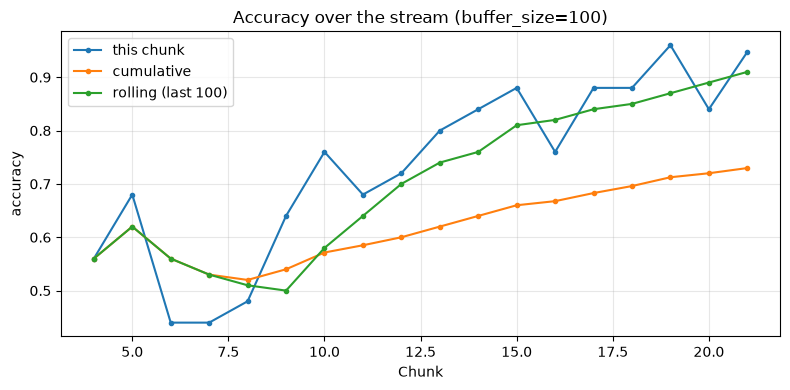

In [9]:
small = trainers[100]
vis.plot_metric_over_time(
    {"this chunk": small.get("accuracy"),
     "cumulative": small.get("cumulative_accuracy"),
     "rolling (last 100)": small.get("rolling_accuracy")},
    title="Accuracy over the stream (buffer_size=100)", ylabel="accuracy",
    save_path=FIGURES / "accuracy_buffer_100.png");

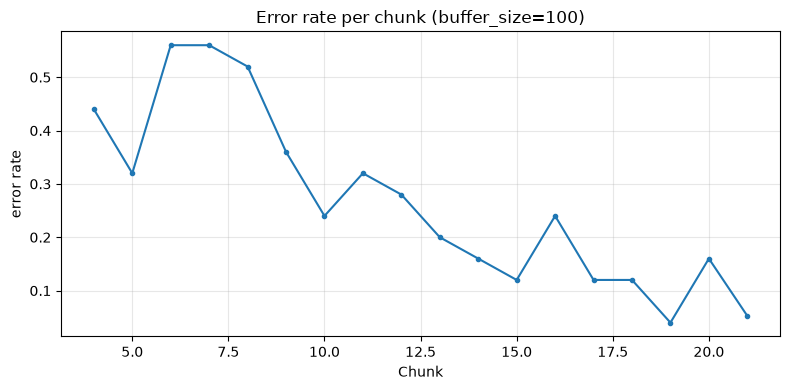

In [10]:
vis.plot_metric_over_time(1 - small.get("accuracy"), title="Error rate per chunk (buffer_size=100)",
                          ylabel="error rate");

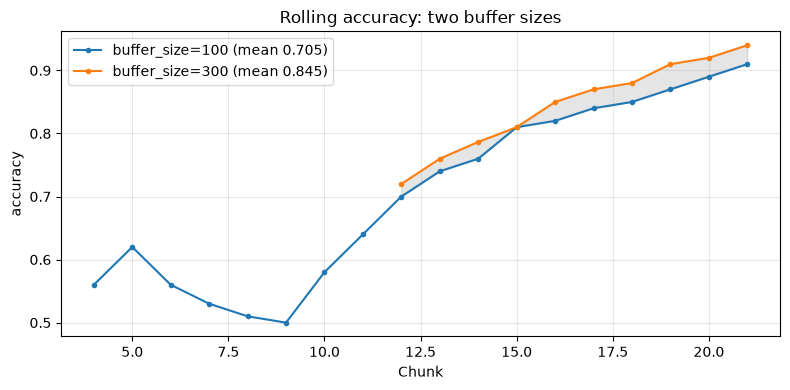

In [11]:
vis.compare_models(trainers[100].get("rolling_accuracy"), trainers[300].get("rolling_accuracy"),
                   labels=("buffer_size=100", "buffer_size=300"), title="Rolling accuracy: two buffer sizes",
                   ylabel="accuracy", save_path=FIGURES / "buffer_100_vs_300.png");

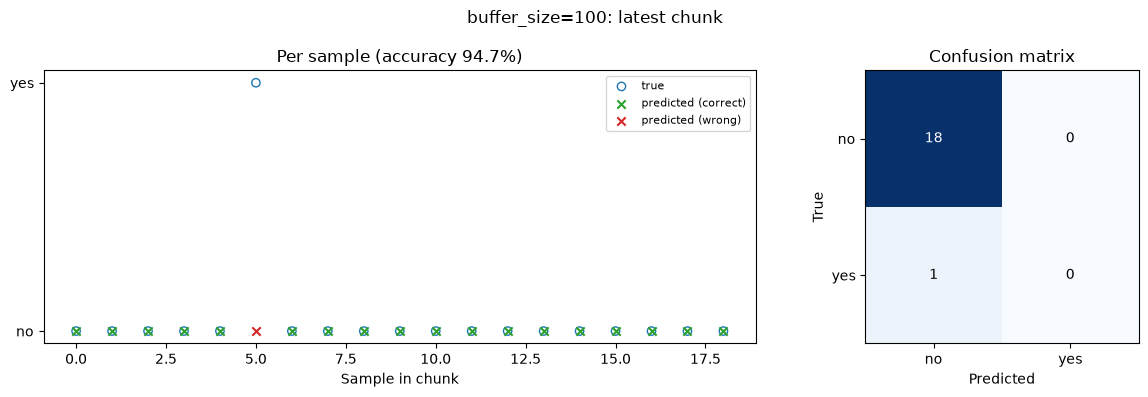

In [12]:
vis.plot_predictions_vs_ground_truth(small.last_y_true, small.last_y_pred,
                                     title="buffer_size=100: latest chunk");

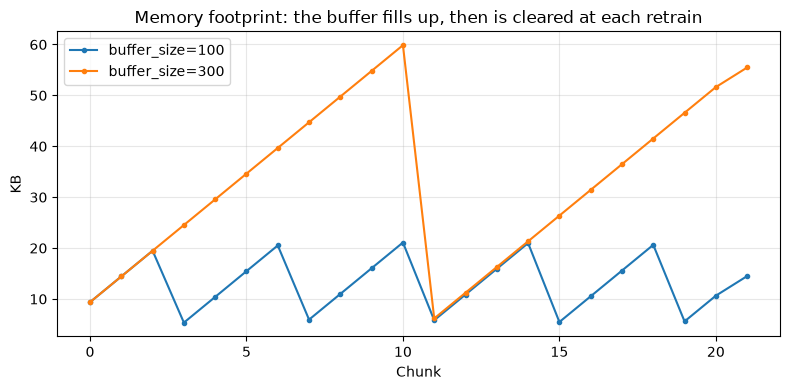

In [13]:
vis.plot_metric_over_time({f"buffer_size={size}": trainer.get("memory_kb") for size, trainer in trainers.items()},
                          title="Memory footprint: the buffer fills up, then is cleared at each retrain", ylabel="KB");

## 7. When does the tree change?
The tree only changes when it retrains. A small buffer retrains often, but each tree learns from few houses. A large buffer retrains rarely, but each tree learns from more.

In [14]:
for buffer_size, trainer in trainers.items():
    retrain_chunks = np.flatnonzero(trainer.get("retrained") == 1).tolist()
    print(f"buffer_size={buffer_size}: retrained after chunks {retrain_chunks}")

buffer_size=100: retrained after chunks [3, 7, 11, 15, 19]
buffer_size=300: retrained after chunks [11]


## 8. AUC accumulated over the stream
`AUC` needs probabilities. This cell tests the tree on each chunk, for the class `yes` against `no`, before training on that chunk.

In [15]:
auc = AUC(pos_label="yes")
pipe = make_pipeline(buffer_size=100)
for X_chunk, y_chunk in chunks:
    if pipe.is_fitted:  # test, then train
        yes_column = list(pipe.classes_).index("yes")
        auc.update(y_chunk, pipe.predict_proba(X_chunk)[:, yes_column])
    pipe.partial_fit(X_chunk, y_chunk)
print(f"AUC for 'yes' over the stream: {auc.result():.3f}  (0.5 = guessing, 1.0 = perfect)")

AUC for 'yes' over the stream: 0.606  (0.5 = guessing, 1.0 = perfect)


## Takeaways
* Every part learns chunk by chunk:
  * the statistics, encoder, imputer and scaler;
  * the buffered tree, which retrains each time `buffer_size` samples are waiting;
  * the metrics.
* `buffer_size` is a trade-off, and the log shows both sides:
  * a small buffer retrains more often (5 times against 1), and each retrain is quicker, with a smaller memory footprint;
  * a large buffer retrains rarely, so it can only start predicting later (chunk 12 against chunk 4), but each tree is trained on more houses.
* **Be careful with the accuracy.** About 69% of the houses have no air conditioning, and in the later chunks (the cheaper houses) about 87% have none. Always answering `no` scores 0.873 on those chunks, and no buffer size here clearly beats it. The AUC of about 0.6 says the same: with 544 houses and a weak signal, the tree learns little about air conditioning.
* The benchmark (`benchmark_stream/stream_buffer_size.md`) repeats the comparison in a shuffled order. There, only the largest buffer (300) clearly beats the baseline, so how many samples each tree sees matters more than how often it retrains.